## Faster R-CNN

We use Faster R-CNN with ResNet50-FPN and pretrained weights, comparing the baseline with variants that use GIoU box loss and a multi-step learning rate scheduler.

We train each variant for 6 epochs on each of the 5 folds, using 4,868 frames (every 5th frame from the videos) and GroupKFold by video. We report the results as mean and standard deviation across the validation folds.

In [ ]:
%pip -q install pycocotools

In [ ]:
import os, io, json, time, random, math, hashlib, shutil, tempfile, types
from collections import defaultdict
from pathlib import Path
from contextlib import redirect_stdout
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
from tqdm import tqdm
from torch.utils.data import Dataset, DataLoader, Sampler
import torchvision
from torchvision.ops import box_iou, generalized_box_iou_loss
from torchvision.transforms import functional as TF
from torchvision.models.detection import fasterrcnn_resnet50_fpn, FasterRCNN_ResNet50_FPN_Weights
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
import torchvision.models.detection.roi_heads as roi_heads_module
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from IPython.display import display

In [ ]:
DATA = (Path('..').resolve() / 'datasets/multiple-object-video-detection-hw-2-ucu-ai-2026')
FOLDS_CSV = (Path('..').resolve() / 'shared/sequence_folds.csv')
OUT = (Path('..').resolve() / 'faster_rcnn')
OUT.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
AMP = DEVICE.type == 'cuda'
MAX_DETS = 100
NUM_WORKERS = 2

In [ ]:
def seed_all(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_all(42)
print('torch:', torch.__version__, '| torchvision:', torchvision.__version__, '| device:', DEVICE)
assert (DATA / 'train/annotations_coco.json').exists(), 'Set DATA to your dataset folder'
assert FOLDS_CSV.exists(), 'Run the shared fold-preparation notebook first'

torch: 2.11.0+cu128 | torchvision: 0.26.0+cu128 | device: cuda


### Data preprocessing

In [ ]:
%%writefile visdrone_data.py
import random
from collections import defaultdict
from pathlib import Path
import numpy as np
import torch
from PIL import Image
from torch.utils.data import Dataset
from torchvision.transforms import functional as TF

In [ ]:
%%writefile -a visdrone_data.py
class VisDrone(Dataset):
    def __init__(self, root, split, coco, image_ids, train=False, seed=42):
        ids = set(map(int, image_ids))
        self.root, self.split = Path(root), split
        self.train, self.seed = train, seed
        self.epoch = 0
        self.images = [image_info for image_info in coco['images'] if int(image_info['id']) in ids]
        cat_ids = sorted(int(category['id']) for category in coco['categories'])
        cat_to_label = {category_id: i + 1 for i, category_id in enumerate(cat_ids)}
        self.objs, self.ign = defaultdict(list), defaultdict(set)
        for annotation in coco['annotations']:
            image_id = int(annotation['image_id'])
            if image_id not in ids:
                continue
            x, y, w, h = map(float, annotation['bbox'])
            if annotation.get('iscrowd', 0):
                self.ign[image_id].add((x, y, x + w, y + h))
            else:
                self.objs[image_id].append((x, y, x + w, y + h, cat_to_label[int(annotation['category_id'])]))

    def __len__(self):
        return len(self.images)

    def get_target(self, i):
        image_info = self.images[i]
        width, height = image_info['width'], image_info['height']
        objects = np.asarray(self.objs[int(image_info['id'])], dtype=np.float32).reshape(-1, 5)
        boxes = objects[:, :4].copy()
        boxes[:, [0, 2]] = boxes[:, [0, 2]].clip(0, width)
        boxes[:, [1, 3]] = boxes[:, [1, 3]].clip(0, height)
        ok = (boxes[:, 2] > boxes[:, 0]) & (boxes[:, 3] > boxes[:, 1])
        ignored_boxes = np.asarray(sorted(self.ign[int(image_info['id'])]), dtype=np.float32).reshape(-1, 4)
        ignored_boxes[:, [0, 2]] = ignored_boxes[:, [0, 2]].clip(0, width)
        ignored_boxes[:, [1, 3]] = ignored_boxes[:, [1, 3]].clip(0, height)
        ignored_boxes = ignored_boxes[(ignored_boxes[:, 2] > ignored_boxes[:, 0]) &
                                      (ignored_boxes[:, 3] > ignored_boxes[:, 1])]
        return dict(boxes=torch.from_numpy(boxes[ok]), labels=torch.from_numpy(objects[ok, 4]).long(),
                    ignored=torch.from_numpy(ignored_boxes), image_id=torch.tensor(int(image_info['id'])))

    def __getitem__(self, i):
        image_info = self.images[i]
        target = self.get_target(i)
        with Image.open(self.root / self.split / image_info['file_name']) as picture:
            img = TF.pil_to_tensor(picture.convert('RGB')).float().div_(255)
        if self.train:
            rng = random.Random(self.seed * 1000003 + self.epoch * 100003 + i)
            if rng.random() < .5:
                img = img.flip(-1)
                w = img.shape[-1]
                boxes = target['boxes'].clone()
                boxes[:, [0, 2]] = w - target['boxes'][:, [2, 0]]
                target['boxes'] = boxes
                ignored = target['ignored'].clone()
                ignored[:, [0, 2]] = w - target['ignored'][:, [2, 0]]
                target['ignored'] = ignored
            if rng.random() < .5:
                img = TF.adjust_brightness(img, rng.uniform(.8, 1.2))
                img = TF.adjust_contrast(img, rng.uniform(.8, 1.2))
                img = TF.adjust_saturation(img, rng.uniform(.8, 1.2))
        return img, target

In [ ]:
%%writefile -a visdrone_data.py
def collate(batch):
    return tuple(zip(*batch))

In [ ]:
import sys
sys.path.insert(0, str(Path('..').resolve() / 'shared'))
from visdrone_data import VisDrone, collate

with open(DATA / 'train/annotations_coco.json') as file:
    coco_train = json.load(file)
with open(DATA / 'val/annotations_coco.json') as file:
    coco_val = json.load(file)
folds = pd.read_csv(FOLDS_CSV)
CATS = {int(category['id']): category['name'] for category in coco_train['categories']}
CAT_IDS = sorted(CATS)
CAT_TO_LABEL = {category_id: i + 1 for i, category_id in enumerate(CAT_IDS)}
LABEL_TO_CAT = {v: k for k, v in CAT_TO_LABEL.items()}
N_CLASSES = len(CATS) + 1
SIZE_NAMES = ['small', 'medium', 'large']

In [ ]:
def size_bucket(area):
    return 0 if area < 32**2 else 1 if area < 96**2 else 2

def make_loader(dataset, batch_size, shuffle=False, workers=NUM_WORKERS):
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle, num_workers=workers,
                      pin_memory=AMP, collate_fn=collate, persistent_workers=False)

In [ ]:
class EpochBatches(Sampler):
    def __init__(self, length, batch_size, seed, epoch, start=0):
        indices = torch.randperm(length, generator=torch.Generator().manual_seed(seed + epoch)).tolist()
        self.batches = [indices[i:i + batch_size] for i in range(0, length, batch_size)]
        self.start = start
    def __iter__(self):
        return iter(self.batches[self.start:])
    def __len__(self):
        return len(self.batches) - self.start

def train_loader(dataset, cfg, epoch, batch_start):
    dataset.epoch = epoch
    batches = EpochBatches(len(dataset), cfg['bs'], cfg['seed'], epoch, batch_start)
    return DataLoader(dataset, batch_sampler=batches, num_workers=NUM_WORKERS,
                      pin_memory=AMP, collate_fn=collate, persistent_workers=False,
                      generator=torch.Generator().manual_seed(cfg['seed'] + epoch))

In [ ]:
FRAME_STEP = 5
images = pd.DataFrame(coco_train['images']).sort_values(['video', 'frame_id']).reset_index(drop=True)
sampled = images[images.groupby('video').cumcount() % FRAME_STEP == 0]
assert folds.id.is_unique and set(folds.id) == set(sampled.id), 'fold file is not the FCOS every-5th-frame sample'
check = folds.merge(sampled, on='id', suffixes=('', '_coco'))
assert all((check[column] == check[column + '_coco']).all() for column in ['video', 'frame_id', 'file_name'])
assert folds.groupby('video').Fold.nunique().max() == 1, 'a video is split across folds'
assert not set(folds.video) & {image_info['video'] for image_info in coco_val['images']}
FOLDS = sorted(int(fold) for fold in folds.Fold.unique())
FOLDS_SHA = hashlib.sha256(FOLDS_CSV.read_bytes()).hexdigest()[:12]

In [ ]:
def fold_ids(fold):
    train_ids = folds.loc[folds.Fold != fold, 'id'].astype(int)
    val_ids = folds.loc[folds.Fold == fold, 'id'].astype(int)
    assert len(train_ids) and len(val_ids) and not (set(train_ids) & set(val_ids))
    return train_ids, val_ids

fold0_train_ids, fold0_val_ids = fold_ids(0)
val_dataset = VisDrone(DATA, 'train', coco_train, fold0_val_ids)
val_loader = make_loader(val_dataset, 4)
print('frames:', len(folds), 'of', len(images), '| videos:', folds.video.nunique(), '| folds:', FOLDS,
      '| fold file:', FOLDS_SHA, '| classes:', N_CLASSES-1)

frames: 4868 of 24201 | videos: 56 | folds: [0, 1, 2, 3, 4] | fold file: 2f1ef1c758e5 | classes: 8


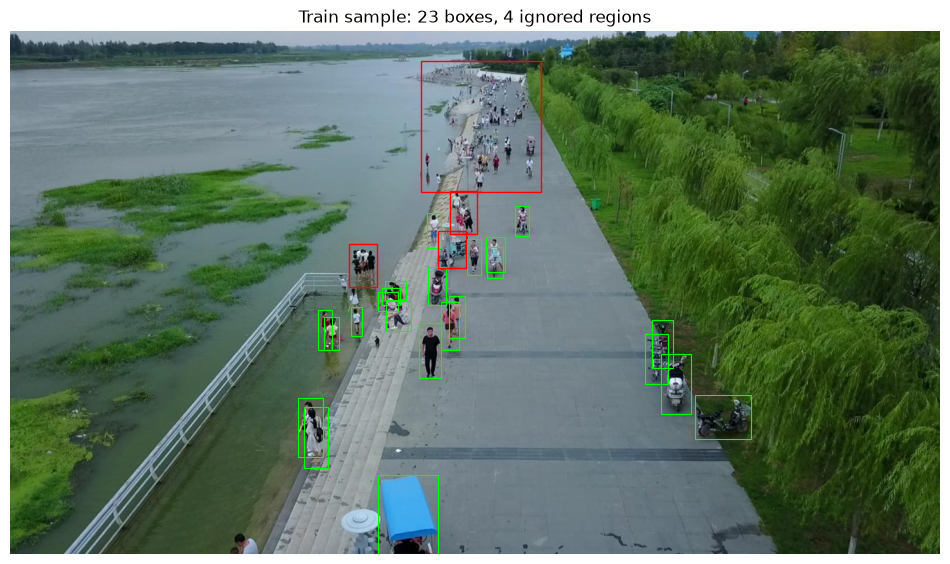

Object sqrt(area) after resize; 1/5/25/50/75/95/99 percentiles: [  8.9  13.5  21.6  30.4  43.8  83.8 130. ]


In [ ]:
sample_dataset = VisDrone(DATA, 'train', coco_train, fold0_train_ids.iloc[:50], train=True)
if len(sample_dataset):
    k = int(np.argmax([len(sample_dataset.ign[int(image_info['id'])])
                       for image_info in sample_dataset.images]))
    img, target = sample_dataset[k]
    fig, ax = plt.subplots(figsize=(12, 7))
    ax.imshow(img.permute(1, 2, 0))
    for x1, y1, x2, y2 in target['boxes'].tolist():
        ax.add_patch(Rectangle((x1, y1), x2-x1, y2-y1, fill=False, edgecolor='lime', linewidth=.8))
    for x1, y1, x2, y2 in target['ignored'].tolist():
        ax.add_patch(Rectangle((x1, y1), x2-x1, y2-y1, fill=False, edgecolor='red', linewidth=1))
    ax.set_title(f"Train sample: {len(target['boxes'])} boxes, {len(target['ignored'])} ignored regions")
    ax.axis('off')
    plt.show()

sampled = coco_train['images'][::20]
scales = {image_info['id']: min(720 / min(image_info['width'], image_info['height']),
                                1280 / max(image_info['width'], image_info['height']))
          for image_info in sampled}
object_sides = np.asarray([math.sqrt(max(annotation['bbox'][2] * annotation['bbox'][3], 0))
                           * scales[annotation['image_id']]
                           for annotation in coco_train['annotations']
                           if not annotation.get('iscrowd', 0) and annotation['image_id'] in scales])
if len(object_sides):
    print('Object sqrt(area) after resize; 1/5/25/50/75/95/99 percentiles:',
          np.percentile(object_sides, [1, 5, 25, 50, 75, 95, 99]).round(1))

### Model

Faster R-CNN has two training stages, RPN and RoI Head, where we exclude negative examples that overlap with ignored regions but keep positive examples matched to annotated objects.

We measure overlap using IoA (intersection area divided by the candidate box area), with the same threshold for all experiments.

In [ ]:
BASE = dict(name='baseline', seed=42, epochs=6, bs=4, lr=.01, wd=1e-4, warmup=300,
            scheduler='cosine', min_size=720, max_size=1280,
            rpn_pre_train=2000, rpn_post_train=2000, rpn_pre_test=1000, rpn_post_test=1000,
            rpn_batch=256, roi_batch=512, roi_pos_frac=.25,
            det_per_img=500, score_thr=.01, nms_thr=.5,
            box_loss='smooth_l1', giou_w=2., ignore_ioa=.5, trainable_layers=3,
            save_every=100)

In [ ]:
_ORIG_LOSS = roi_heads_module.fastrcnn_loss
_BOX_WEIGHTS = (10., 10., 5., 5.)

def decode_unit(deltas):
    deltas = deltas.float() / deltas.new_tensor(_BOX_WEIGHTS)
    dw = deltas[:, 2].clamp(max=math.log(1000 / 16))
    dh = deltas[:, 3].clamp(max=math.log(1000 / 16))
    cx, cy = deltas[:, 0], deltas[:, 1]
    w, h = dw.exp(), dh.exp()
    return torch.stack([cx-w/2, cy-h/2, cx+w/2, cy+h/2], dim=1)

def make_giou_loss(weight):
    def fastrcnn_giou(class_logits, box_regression, labels, regression_targets):
        labels = torch.cat(labels, dim=0)
        regression_targets = torch.cat(regression_targets, dim=0)
        cls_loss = F.cross_entropy(class_logits, labels)
        positive = torch.where(labels > 0)[0]
        num_rois = class_logits.shape[0]
        pred_deltas = box_regression.reshape(num_rois, -1, 4)[positive, labels[positive]]
        if len(positive):
            reg_loss = generalized_box_iou_loss(decode_unit(pred_deltas),
                                                decode_unit(regression_targets[positive]), reduction='sum')
            reg_loss = reg_loss / max(labels.numel(), 1)
        else:
            reg_loss = box_regression.sum() * 0
        return cls_loss, weight * reg_loss
    return fastrcnn_giou

In [ ]:
def ignore_negatives(candidates, labels, ignored, threshold):
    if not len(ignored):
        return labels
    negative = torch.where(labels == 0)[0]
    if not len(negative):
        return labels
    labels = labels.clone()
    for chunk in negative.split(2048):
        boxes = candidates[chunk]
        left_top = torch.maximum(boxes[:, None, :2], ignored[None, :, :2])
        right_bottom = torch.minimum(boxes[:, None, 2:], ignored[None, :, 2:])
        overlap_size = (right_bottom - left_top).clamp(min=0)
        intersection = overlap_size[..., 0] * overlap_size[..., 1]
        area = ((boxes[:, 2] - boxes[:, 0]).clamp(min=1e-6) *
                (boxes[:, 3] - boxes[:, 1]).clamp(min=1e-6))
        inside = (intersection / area[:, None]).amax(dim=1) >= threshold
        labels[chunk[inside]] = -1
    return labels

In [ ]:
def add_ignore_aware_training(model, threshold):
    standard_transform = model.transform.forward

    def transform_with_ignore(self, images, targets=None):
        original_sizes = [image.shape[-2:] for image in images]
        transformed, targets = standard_transform(images, targets)
        if targets is not None:
            for target, (old_h, old_w), (new_h, new_w) in zip(
                    targets, original_sizes, transformed.image_sizes):
                boxes = target['ignored'].clone()
                boxes[:, [0, 2]] *= new_w / old_w
                boxes[:, [1, 3]] *= new_h / old_h
                target['ignored'] = boxes
        return transformed, targets

    model.transform.forward = types.MethodType(transform_with_ignore, model.transform)

    standard_rpn_assign = model.rpn.assign_targets_to_anchors

    def rpn_assign(self, anchors, targets):
        labels, matched_boxes = standard_rpn_assign(anchors, targets)
        for i, target in enumerate(targets):
            labels[i] = ignore_negatives(anchors[i], labels[i],
                                         target['ignored'], threshold)
        return labels, matched_boxes

    model.rpn.assign_targets_to_anchors = types.MethodType(rpn_assign, model.rpn)

    standard_roi_assign = model.roi_heads.assign_targets_to_proposals
    standard_roi_sample = model.roi_heads.select_training_samples

    def roi_assign(self, proposals, gt_boxes, gt_labels):
        matched_ids, labels = standard_roi_assign(proposals, gt_boxes, gt_labels)
        for i, ignored in enumerate(self._ignored_for_sampling):
            labels[i] = ignore_negatives(proposals[i], labels[i], ignored, threshold)
        return matched_ids, labels

    def roi_sample(self, proposals, targets):
        self._ignored_for_sampling = [target['ignored'] for target in targets]
        try:
            return standard_roi_sample(proposals, targets)
        finally:
            del self._ignored_for_sampling

    model.roi_heads.assign_targets_to_proposals = types.MethodType(roi_assign, model.roi_heads)
    model.roi_heads.select_training_samples = types.MethodType(roi_sample, model.roi_heads)
    return model

In [ ]:
def build_model(cfg):
    model = fasterrcnn_resnet50_fpn(
        weights=FasterRCNN_ResNet50_FPN_Weights.DEFAULT,
        trainable_backbone_layers=cfg['trainable_layers'],
        min_size=cfg['min_size'], max_size=cfg['max_size'],
        rpn_pre_nms_top_n_train=cfg['rpn_pre_train'], rpn_post_nms_top_n_train=cfg['rpn_post_train'],
        rpn_pre_nms_top_n_test=cfg['rpn_pre_test'], rpn_post_nms_top_n_test=cfg['rpn_post_test'],
        rpn_batch_size_per_image=cfg['rpn_batch'],
        box_batch_size_per_image=cfg['roi_batch'], box_positive_fraction=cfg['roi_pos_frac'],
        box_detections_per_img=cfg['det_per_img'], box_score_thresh=cfg['score_thr'],
        box_nms_thresh=cfg['nms_thr'])
    model.roi_heads.box_predictor = FastRCNNPredictor(model.roi_heads.box_predictor.cls_score.in_features, N_CLASSES)
    roi_heads_module.fastrcnn_loss = (make_giou_loss(cfg['giou_w'])
                                      if cfg['box_loss'] == 'giou' else _ORIG_LOSS)
    add_ignore_aware_training(model, cfg['ignore_ioa'])
    return model

def set_inference(model, rpn_proposals=None, max_detections=None, nms_threshold=None, score_threshold=None):
    if rpn_proposals is not None:
        model.rpn._post_nms_top_n['testing'] = rpn_proposals
        model.rpn._pre_nms_top_n['testing'] = max(model.rpn._pre_nms_top_n['testing'], rpn_proposals)
    if max_detections is not None:
        model.roi_heads.detections_per_img = max_detections
    if nms_threshold is not None:
        model.roi_heads.nms_thresh = nms_threshold
    if score_threshold is not None:
        model.roi_heads.score_thresh = score_threshold

In [ ]:
ignore_box = torch.tensor([[10., 10., 50., 50.]])
candidates = torch.tensor([[15., 15., 30., 30.], [60., 60., 80., 80.],
                           [15., 15., 30., 30.]])
labels = torch.tensor([0, 0, 1])
checked = ignore_negatives(candidates, labels, ignore_box, BASE['ignore_ioa'])
assert checked.tolist() == [-1, 0, 1]
assert BASE['det_per_img'] >= MAX_DETS
print('Ignore-aware check passed: overlapping negatives ignored, positives kept.')

Ignore-aware check passed: overlapping negatives ignored, positives kept.


### Training and evaluation

In [ ]:
def make_gt(coco, ids):
    ids = set(map(int, ids))
    annotations = []
    for annotation in coco['annotations']:
        if int(annotation['image_id']) not in ids:
            continue
        x, y, w, h = map(float, annotation['bbox'])
        if w <= 0 or h <= 0:
            continue
        item = dict(annotation)
        item['area'] = float(annotation.get('area', w*h))
        item['iscrowd'] = int(annotation.get('iscrowd', 0))
        annotations.append(item)
    for j, annotation in enumerate(annotations):
        annotation['id'] = j + 1
    gt = COCO()
    gt.dataset = dict(info={}, licenses=[],
                      images=[image_info for image_info in coco['images'] if int(image_info['id']) in ids],
                      annotations=annotations, categories=coco['categories'])
    with redirect_stdout(io.StringIO()):
        gt.createIndex()
    return gt

val_gt = make_gt(coco_train, fold0_val_ids)

In [ ]:
@torch.inference_mode()
def predict(model, loader, verbose=False):
    model.eval()
    rows = []
    for images, targets in tqdm(loader, desc='Predict', leave=False, disable=not verbose):
        with torch.autocast(device_type=DEVICE.type, enabled=AMP):
            preds = model([image.to(DEVICE, non_blocking=True) for image in images])
        for prediction, target in zip(preds, targets):
            rows.append((int(target['image_id']), {k: v.detach().cpu() for k, v in prediction.items()}))
    return rows

In [ ]:
def coco_metrics(preds, gt):
    detections = []
    for image_id, prediction in preds:
        for box, score, label in zip(prediction['boxes'].tolist(), prediction['scores'].tolist(),
                                     prediction['labels'].tolist()):
            x1, y1, x2, y2 = box
            if x2 <= x1 or y2 <= y1:
                continue
            detections.append(dict(image_id=image_id, category_id=LABEL_TO_CAT[int(label)],
                                   bbox=[x1, y1, x2-x1, y2-y1], score=float(score)))
    keys = ['mAP', 'AP50', 'AP75', 'APs', 'APm', 'APl', 'AR']
    if not detections:
        return {**{k: 0. for k in keys}, 'per_class': {v: 0. for v in CATS.values()}}
    with redirect_stdout(io.StringIO()):
        evaluation = COCOeval(gt, gt.loadRes(detections), 'bbox')
        evaluation.params.imgIds = sorted(gt.getImgIds())
        evaluation.params.maxDets = [1, 10, MAX_DETS]
        evaluation.evaluate()
        evaluation.accumulate()
        evaluation.summarize()
    precision = evaluation.eval['precision'][:, :, :, 0, -1]
    per_class = {}
    for k, category_id in enumerate(evaluation.params.catIds):
        values = precision[:, :, k]
        per_class[CATS[category_id]] = float(values[values > -1].mean()) if (values > -1).any() else float('nan')
    stats = evaluation.stats
    return dict(mAP=float(precision[precision > -1].mean()), AP50=float(stats[1]), AP75=float(stats[2]),
                APs=float(stats[3]), APm=float(stats[4]), APl=float(stats[5]), AR=float(stats[8]), per_class=per_class)

In [ ]:
@torch.inference_mode()
def measure_speed(model, dataset, num_images=40, warmup_steps=8):
    model.eval()
    images = [dataset[(i * 7) % len(dataset)][0].to(DEVICE)
              for i in range(min(num_images+warmup_steps, len(dataset)))]
    times = []
    for i, image in enumerate(images):
        if DEVICE.type == 'cuda':
            torch.cuda.synchronize()
        start = time.perf_counter()
        with torch.autocast(device_type=DEVICE.type, enabled=AMP):
            model([image])
        if DEVICE.type == 'cuda':
            torch.cuda.synchronize()
        times.append(time.perf_counter() - start)
    return float(np.mean(times[min(warmup_steps, max(0, len(times)-1)):]) * 1000)

In [ ]:
def save_atomic(obj, path, keep_backup=True):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    file_descriptor, tmp_path = tempfile.mkstemp(prefix='.tmp_', suffix=path.suffix, dir=path.parent)
    os.close(file_descriptor)
    try:
        if path.suffix == '.json':
            with open(tmp_path, 'w') as file:
                json.dump(obj, file, indent=2)
                file.flush()
                os.fsync(file.fileno())
        else:
            torch.save(obj, tmp_path)
        if keep_backup and path.exists():
            backup_tmp = str(path) + '.bak.tmp'
            shutil.copy2(path, backup_tmp)
            os.replace(backup_tmp, str(path) + '.bak')
        os.replace(tmp_path, path)
    finally:
        if os.path.exists(tmp_path):
            os.unlink(tmp_path)

def cfg_id(cfg):
    stable = {k: v for k, v in cfg.items() if k != 'save_every'}
    return hashlib.sha256(json.dumps(stable, sort_keys=True).encode()).hexdigest()

In [ ]:
def lr_schedule(cfg, total_steps):
    warmup_steps = max(1, min(cfg['warmup'], total_steps // 4))
    def factor(step):
        step = min(step + 1, total_steps)
        if step < warmup_steps:
            return step / warmup_steps
        progress = (step - warmup_steps) / max(total_steps - warmup_steps, 1)
        if cfg['scheduler'] == 'cosine':
            return .01 + .99 * .5 * (1 + math.cos(math.pi * progress))
        if cfg['scheduler'] == 'multistep':
            return 1. if progress < .6 else (.1 if progress < .85 else .01)
        raise ValueError('Unknown scheduler: ' + cfg['scheduler'])
    return factor

In [ ]:
def read_checkpoint(folder, identity):
    for path in [folder / 'last.pth', folder / 'last.pth.bak']:
        if not path.exists():
            continue
        try:
            checkpoint_data = torch.load(path, map_location='cpu', weights_only=False)
            if checkpoint_data.get('cfg_id') != identity:
                raise ValueError(f'Checkpoint config mismatch: {path}')
            if path.suffix == '.bak':
                print('Recovered from backup:', path)
            return checkpoint_data
        except (EOFError, RuntimeError, OSError, ValueError, KeyError) as error:
            print('Cannot use checkpoint:', path, '|', error)
    return None

In [ ]:
def run_experiment(overrides, fold):
    cfg = {**BASE, **overrides, 'fold': int(fold), 'folds': FOLDS_SHA}
    run = f"{cfg['name']}/fold{fold}"
    folder = OUT / cfg['name'] / f'fold{fold}'
    folder.mkdir(parents=True, exist_ok=True)
    identity = cfg_id(cfg)
    config_file, result_file = folder / 'config.json', folder / 'result.json'
    if config_file.exists():
        with open(config_file) as file:
            old_cfg = json.load(file)
        if cfg_id(old_cfg) != identity:
            raise ValueError(f"{run}: different configuration already exists. Use a NEW run name.")
    else:
        if any(folder.iterdir()):
            raise FileExistsError(f'{folder} has files but no config: refusing to overwrite')
        save_atomic(cfg, config_file, keep_backup=False)
    if result_file.exists():
        with open(result_file) as file:
            result = json.load(file)
        if cfg_id(result['cfg']) != identity:
            raise ValueError('Existing result does not match the requested configuration')
        print(run, ': result already exists — skipping training')
        return result

    seed_all(cfg['seed'])
    model = build_model(cfg).to(DEVICE)
    fold_train_ids, fold_val_ids = fold_ids(fold)
    dataset = VisDrone(DATA, 'train', coco_train, fold_train_ids, train=True, seed=cfg['seed'])
    fold_val_dataset = VisDrone(DATA, 'train', coco_train, fold_val_ids)
    fold_loader, fold_gt = make_loader(fold_val_dataset, 4), make_gt(coco_train, fold_val_ids)
    batches_per_epoch = math.ceil(len(dataset) / cfg['bs'])
    print(f"{run}: {len(dataset)} training frames, {len(fold_val_dataset)} validation frames, {batches_per_epoch} batches per epoch")
    total_steps = batches_per_epoch * cfg['epochs']
    params = [param for param in model.parameters() if param.requires_grad]
    optimizer = torch.optim.SGD(params, lr=cfg['lr'], momentum=.9, weight_decay=cfg['wd'])
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_schedule(cfg, total_steps))
    scaler = torch.amp.GradScaler('cuda', enabled=AMP)
    history, epoch, batch_start, sums, seen = [], 0, 0, {}, 0
    checkpoint_data = read_checkpoint(folder, identity)
    if checkpoint_data is not None:
        model.load_state_dict(checkpoint_data['model'])
        optimizer.load_state_dict(checkpoint_data['optimizer'])
        scheduler.load_state_dict(checkpoint_data['scheduler'])
        scaler.load_state_dict(checkpoint_data['scaler'])
        history = checkpoint_data['history']
        epoch, batch_start = checkpoint_data['epoch'], checkpoint_data['batch_start']
        sums, seen = checkpoint_data['sums'], checkpoint_data['seen']
        if 'torch_rng' in checkpoint_data:
            torch.set_rng_state(checkpoint_data['torch_rng'])
            np.random.set_state(checkpoint_data['numpy_rng'])
            random.setstate(checkpoint_data['python_rng'])
            if DEVICE.type == 'cuda' and checkpoint_data.get('cuda_rng') is not None:
                torch.cuda.set_rng_state_all(checkpoint_data['cuda_rng'])
        print(f"{run}: resume at epoch {epoch+1}, batch {batch_start+1}/{batches_per_epoch}")

    def checkpoint(current_epoch, batch, losses, count):
        state = dict(cfg_id=identity, model=model.state_dict(), optimizer=optimizer.state_dict(),
                     scheduler=scheduler.state_dict(), scaler=scaler.state_dict(),
                     history=history, epoch=current_epoch, batch_start=batch, sums=dict(losses), seen=count,
                     torch_rng=torch.get_rng_state(), numpy_rng=np.random.get_state(),
                     python_rng=random.getstate(),
                     cuda_rng=torch.cuda.get_rng_state_all() if DEVICE.type == 'cuda' else None)
        save_atomic(state, folder / 'last.pth')

    try:
        for current_epoch in range(epoch, cfg['epochs']):
            start_batch = batch_start if current_epoch == epoch else 0
            epoch_loss_sums = defaultdict(float, sums if current_epoch == epoch else {})
            count = seen if current_epoch == epoch else 0
            model.train()
            loader = train_loader(dataset, cfg, current_epoch, start_batch)
            for batch_index, (images, targets) in enumerate(tqdm(loader, desc=f"{run} {current_epoch+1}/{cfg['epochs']}"),
                                                            start=start_batch):
                images = [image.to(DEVICE, non_blocking=True) for image in images]
                targets = [{'boxes': target['boxes'].to(DEVICE), 'labels': target['labels'].to(DEVICE),
                            'ignored': target['ignored'].to(DEVICE)} for target in targets]
                optimizer.zero_grad(set_to_none=True)
                with torch.autocast(device_type=DEVICE.type, enabled=AMP):
                    losses = model(images, targets)
                    loss = sum(losses.values())
                if not torch.isfinite(loss):
                    checkpoint(current_epoch, batch_index, epoch_loss_sums, count)
                    raise RuntimeError(f"Non-finite loss in {run} epoch {current_epoch+1} batch {batch_index+1}")
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(params, 10.)
                before = scaler.get_scale()
                scaler.step(optimizer)
                scaler.update()
                if not AMP or scaler.get_scale() >= before:
                    scheduler.step()
                for k, v in losses.items():
                    epoch_loss_sums[k] += float(v.detach())
                count += 1
                if (batch_index + 1) % cfg['save_every'] == 0:
                    checkpoint(current_epoch, batch_index + 1, epoch_loss_sums, count)
            checkpoint(current_epoch, batches_per_epoch, epoch_loss_sums, count)
            metrics = coco_metrics(predict(model, fold_loader), fold_gt)
            history.append(dict(epoch=current_epoch+1, **{k: v/max(count, 1) for k, v in epoch_loss_sums.items()},
                                loss=sum(epoch_loss_sums.values())/max(count, 1),
                                **{k: metrics[k] for k in ['mAP', 'AP50', 'APs', 'APm', 'APl']},
                                lr=optimizer.param_groups[0]['lr']))
            if metrics['mAP'] > max((epoch_record['mAP'] for epoch_record in history[:-1]), default=-1.):
                save_atomic(dict(cfg_id=identity, model=model.state_dict(), epoch=current_epoch+1, metrics=metrics),
                            folder / 'best.pth', keep_backup=False)
            best_epoch = max(history, key=lambda epoch_record: epoch_record['mAP'])['epoch']
            print(f"{run} epoch {current_epoch+1}: mAP={metrics['mAP']:.4f} AP50={metrics['AP50']:.4f} "
                  f"AP_small={metrics['APs']:.4f} AP_medium={metrics['APm']:.4f} AP_large={metrics['APl']:.4f} "
                  f"| best epoch {best_epoch}")
            checkpoint(current_epoch + 1, 0, {}, 0)
            batch_start, sums, seen = 0, {}, 0
        best = torch.load(folder / 'best.pth', map_location='cpu', weights_only=False)
        model.load_state_dict(best['model'])
        result = dict(name=cfg['name'], fold=int(fold), cfg=cfg, history=history,
                      best_epoch=best['epoch'], metrics=best['metrics'],
                      train_frames=len(dataset), val_frames=len(fold_val_dataset),
                      ms_per_img=measure_speed(model, fold_val_dataset),
                      n_params_M=sum(param.numel() for param in model.parameters()) / 1e6)
        save_atomic(result, result_file, keep_backup=False)
        return result
    finally:
        del model, optimizer
        if DEVICE.type == 'cuda':
            torch.cuda.empty_cache()

In [ ]:
def load_model(name, fold=0, **inference):
    folder = OUT / name / f'fold{fold}'
    with open(folder / 'config.json') as file:
        cfg = json.load(file)
    checkpoint_data = torch.load(folder / 'best.pth', map_location='cpu', weights_only=False)
    if checkpoint_data['cfg_id'] != cfg_id(cfg):
        raise ValueError(f'best.pth does not match the configuration of {name}/fold{fold}')
    model = build_model(cfg)
    model.load_state_dict(checkpoint_data['model'])
    set_inference(model, **inference)
    return model.to(DEVICE).eval()

### Experiments


```
# Має бути у форматі коду
```


| Run | Change |
|---|---|
| baseline | Original Faster R-CNN |
| giou_loss | GIoU box regression loss |
| lr_scheduler | Multi-step learning rate schedule |

In [ ]:
EXPERIMENTS = [
    dict(name='baseline'),
    dict(name='giou_loss', box_loss='giou'),
    dict(name='lr_scheduler', scheduler='multistep'),
]

In [ ]:
fold_table = pd.DataFrame([
    dict(fold=fold, train_videos=folds.loc[folds.Fold != fold, 'video'].nunique(),
         train_frames=int((folds.Fold != fold).sum()),
         val_videos=folds.loc[folds.Fold == fold, 'video'].nunique(), val_frames=int((folds.Fold == fold).sum()),
         batches_per_epoch=math.ceil((folds.Fold != fold).sum() / BASE['bs']))
    for fold in FOLDS]).set_index('fold')
display(fold_table)
results = {}
for fold in FOLDS:
    for change in EXPERIMENTS:
        results[change['name'], fold] = run_experiment(change, fold)
print('Finished runs:', len(results))

,train_videos,train_frames,val_videos,val_frames,batches_per_epoch
fold,,,,,
0,45,3887,11,981,972
1,45,3889,11,979,973
2,45,3905,11,963,977
3,44,3894,12,974,974
4,45,3897,11,971,975


baseline/fold0 : result already exists — skipping training
giou_loss/fold0 : result already exists — skipping training
lr_scheduler/fold0 : result already exists — skipping training
baseline/fold1 : result already exists — skipping training
giou_loss/fold1 : result already exists — skipping training
lr_scheduler/fold1 : result already exists — skipping training
baseline/fold2 : result already exists — skipping training
giou_loss/fold2 : result already exists — skipping training
lr_scheduler/fold2 : result already exists — skipping training
baseline/fold3 : result already exists — skipping training
giou_loss/fold3 : result already exists — skipping training
lr_scheduler/fold3 : result already exists — skipping training
baseline/fold4 : result already exists — skipping training
giou_loss/fold4 : result already exists — skipping training
lr_scheduler/fold4 : result already exists — skipping training
Finished runs: 15


In [ ]:
rows = []
def sweep(knob, value, **settings):
    model = load_model('baseline', **settings)
    metrics = coco_metrics(predict(model, val_loader), val_gt)
    rows.append(dict(knob=knob, value=value, mAP=metrics['mAP'], AP50=metrics['AP50'],
                     APs=metrics['APs'], AR=metrics['AR'], ms_per_img=measure_speed(model, val_dataset)))
    del model
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()

In [ ]:
for count in [100, 300, 1000, 2000, 3000]:
    sweep('rpn_proposals_test', count, rpn_proposals=count)
for count in [100, 300, 500]:
    sweep('detections_per_img', count, max_detections=count)
for threshold in [.4, .5, .6, .7]:
    sweep('roi_nms_thresh', threshold, nms_threshold=threshold)
sweep_df = pd.DataFrame(rows)
display(sweep_df.round(4))
sweep_df.to_csv(OUT / 'inference_sweep.csv', index=False)

,knob,value,mAP,AP50,APs,AR,ms_per_img
0,rpn_proposals_test,100.0,0.2165,0.3921,0.0946,0.3226,26.3180
1,rpn_proposals_test,300.0,0.2321,0.4306,0.0992,0.3653,26.4085
2,rpn_proposals_test,1000.0,0.2332,0.4328,0.0993,0.3717,27.0333
3,rpn_proposals_test,2000.0,0.2348,0.4391,0.0994,0.3827,29.2939
4,rpn_proposals_test,3000.0,0.2350,0.4408,0.0996,0.3876,32.5923
5,detections_per_img,100.0,0.2256,0.4151,0.0988,0.3449,26.9502
6,detections_per_img,300.0,0.2332,0.4328,0.0993,0.3717,26.6049
7,detections_per_img,500.0,0.2332,0.4328,0.0993,0.3717,27.2308
8,roi_nms_thresh,0.4,0.2328,0.4318,0.0994,0.3683,26.3366
9,roi_nms_thresh,0.5,0.2332,0.4328,0.0993,0.3717,26.6236


### Results


In [ ]:
KEYS = ['mAP', 'AP50', 'AP75', 'APs', 'APm', 'APl', 'AR']

def mean_std(df):
    stats = df.drop(columns='fold').groupby('run').agg(['mean', 'std'])
    stats = stats.sort_values(('mAP', 'mean'), ascending=False)
    table = pd.DataFrame({k: stats[k, 'mean'].map('{:.4f}'.format) + ' ± ' + stats[k, 'std'].map('{:.4f}'.format)
                          for k in stats.columns.get_level_values(0).unique()})
    return stats, table

In [ ]:
all_results = {(result['name'], result['fold']): result
               for result in (json.loads(path.read_text()) for path in sorted(OUT.glob('*/fold*/result.json')))}
missing = [(experiment['name'], fold) for experiment in EXPERIMENTS for fold in FOLDS
           if (experiment['name'], fold) not in all_results]
print('Runs found:', len(all_results), '| missing:', missing or 'none')
fold_df = pd.DataFrame([dict(run=name, fold=fold, best_epoch=result['best_epoch'],
                             **{k: result['metrics'][k] for k in KEYS},
                             loss=result['history'][result['best_epoch'] - 1]['loss'],
                             ms_per_img=result['ms_per_img'])
                        for (name, fold), result in all_results.items()])
fold_df.to_csv(OUT / 'fold_results.csv', index=False)
display(fold_df.pivot(index='run', columns='fold', values='best_epoch').add_prefix('fold '))
summary, summary_table = mean_std(fold_df)
summary.to_csv(OUT / 'cv_summary.csv')
summary_table.to_csv(OUT / 'cv_summary_mean_std.csv')
display(summary_table)
per_class = pd.DataFrame([dict(run=name, **result['metrics']['per_class'])
                          for (name, _), result in all_results.items()])
per_class = per_class.groupby('run').mean()
per_class.to_csv(OUT / 'per_class_mean.csv')
display(per_class.round(3))
BEST = summary.index[0]
print('Best experiment by mean fold mAP:', BEST)

Runs found: 15 | missing: none


fold,fold 0,fold 1,fold 2,fold 3,fold 4
run,,,,,
baseline,5,1,6,5,5
giou_loss,4,1,4,3,4
lr_scheduler,5,5,4,4,4


,best_epoch,mAP,AP50,AP75,APs,APm,APl,AR,loss,ms_per_img
run,,,,,,,,,,
lr_scheduler,4.4000 ± 0.5477,0.2110 ± 0.0337,0.4137 ± 0.0489,0.1925 ± 0.0410,0.0757 ± 0.0276,0.1981 ± 0.0132,0.3856 ± 0.0507,0.3450 ± 0.0404,0.6248 ± 0.0408,25.7080 ± 0.8222
giou_loss,3.2000 ± 1.3038,0.2100 ± 0.0348,0.4148 ± 0.0524,0.1903 ± 0.0415,0.0727 ± 0.0241,0.1943 ± 0.0161,0.3828 ± 0.0476,0.3500 ± 0.0521,0.4778 ± 0.1481,47.9212 ± 43.3042
baseline,4.4000 ± 1.9494,0.2080 ± 0.0352,0.4106 ± 0.0515,0.1887 ± 0.0430,0.0740 ± 0.0271,0.1953 ± 0.0144,0.3839 ± 0.0405,0.3513 ± 0.0567,0.6748 ± 0.2286,32.6746 ± 12.5547


,person,bicycle,car,van,truck,tricycle,bus,motor
run,,,,,,,,
baseline,0.187,0.057,0.433,0.189,0.108,0.203,0.368,0.118
giou_loss,0.193,0.057,0.428,0.188,0.120,0.200,0.372,0.121
lr_scheduler,0.193,0.060,0.436,0.190,0.124,0.207,0.355,0.124


Best experiment by mean fold mAP: lr_scheduler


In [ ]:
history = pd.concat([pd.DataFrame(result['history']).assign(run=name, fold=fold)
                     for (name, fold), result in all_results.items()])
history.to_csv(OUT / 'epoch_history.csv', index=False)
curves = history.groupby(['run', 'epoch'])[['mAP', 'APs', 'loss']].agg(['mean', 'std'])

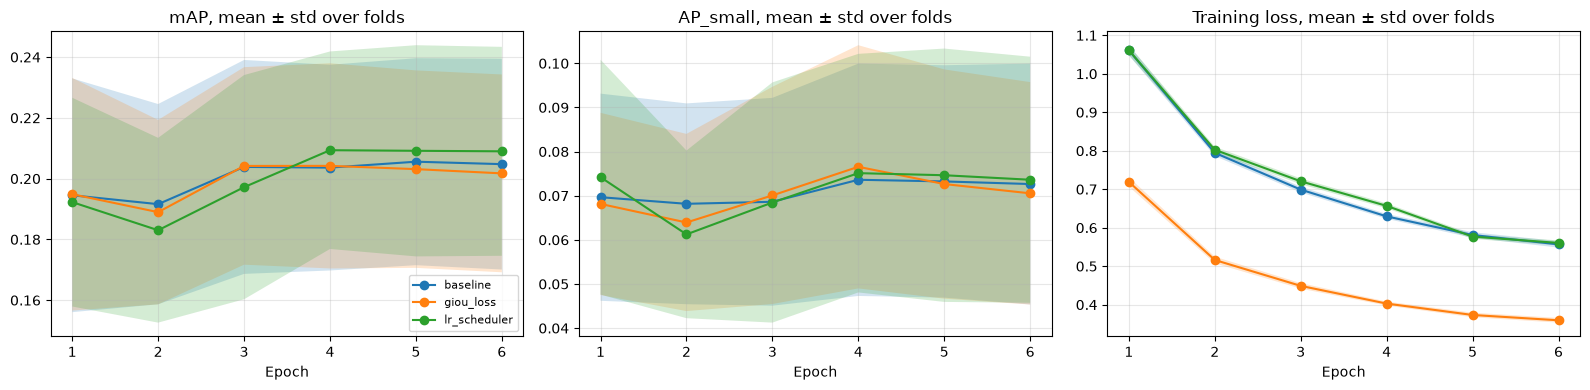

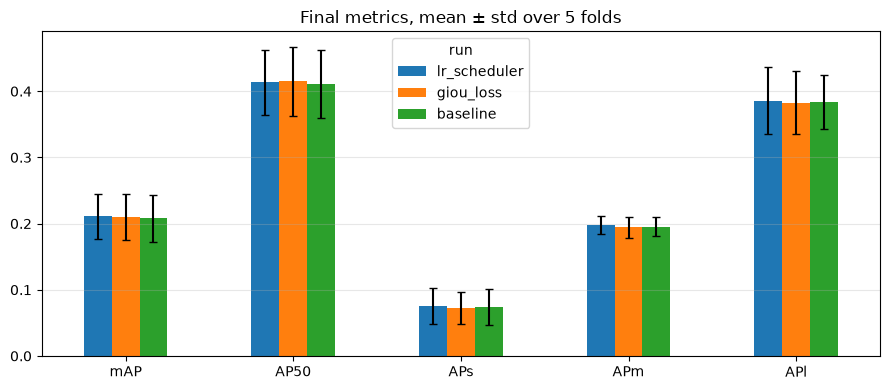

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for name in curves.index.get_level_values(0).unique():
    for ax, key in zip(axes, ['mAP', 'APs', 'loss']):
        mean, std = curves.loc[name][key, 'mean'], curves.loc[name][key, 'std'].fillna(0)
        ax.plot(mean.index, mean, marker='o', label=name)
        ax.fill_between(mean.index, mean - std, mean + std, alpha=.2)
for ax, title in zip(axes, ['mAP', 'AP_small', 'Training loss']):
    ax.set_title(title + ', mean ± std over folds')
    ax.set_xlabel('Epoch')
    ax.grid(alpha=.3)
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.savefig(OUT / 'learning_curves.png', dpi=150)
plt.show()

metric_columns = ['mAP', 'AP50', 'APs', 'APm', 'APl']
ax = summary.xs('mean', axis=1, level=1)[metric_columns].T.plot.bar(
    yerr=summary.xs('std', axis=1, level=1)[metric_columns].T, capsize=3, figsize=(9, 4), rot=0)
ax.set_title('Final metrics, mean ± std over 5 folds')
ax.grid(axis='y', alpha=.3)
plt.tight_layout()
plt.savefig(OUT / 'cv_comparison.png', dpi=150)
plt.show()

### RPN proposals

The RPN proposes candidate boxes; the second stage classifies and refines them. Here we check how many true objects the proposals cover (best experiment, fold-0 model on its held-out fold).

In [ ]:
@torch.inference_mode()
def proposal_recall(model, dataset, proposal_counts=(100, 300, 1000, 2000), num_images=300):
    proposal_counts = sorted(proposal_counts)
    set_inference(model, rpn_proposals=max(proposal_counts))
    model.eval()
    hits = {top_n: np.zeros(3, dtype=float) for top_n in proposal_counts}
    totals = np.zeros(3, dtype=float)
    for i in np.unique(np.linspace(0, len(dataset)-1, min(num_images, len(dataset))).astype(int)):
        image, target = dataset[int(i)]
        boxes = target['boxes']
        if not len(boxes):
            continue
        area = (boxes[:, 2]-boxes[:, 0]) * (boxes[:, 3]-boxes[:, 1])
        sizes = np.array([size_bucket(box_area) for box_area in area.tolist()])
        inputs, transformed = model.transform(
            [image.to(DEVICE)], [{'boxes': boxes.to(DEVICE), 'labels': target['labels'].to(DEVICE),
                           'ignored': target['ignored'].to(DEVICE)}])
        features = model.backbone(inputs.tensors)
        proposals, _ = model.rpn(inputs, features)
        ious = box_iou(transformed[0]['boxes'], proposals[0]).cpu()
        for top_n in proposal_counts:
            ok = (ious[:, :top_n].max(dim=1).values >= .5).numpy() if ious.shape[1] else np.zeros(len(boxes), bool)
            for size_index in range(3):
                hits[top_n][size_index] += np.logical_and(ok, sizes == size_index).sum()
        for size_index in range(3):
            totals[size_index] += (sizes == size_index).sum()
    table = pd.DataFrame({f'top-{top_n}': hits[top_n]/np.maximum(totals, 1) for top_n in proposal_counts},
                         index=SIZE_NAMES)
    table['n_gt'] = totals.astype(int)
    return table

In [ ]:
rpn_model = load_model(BEST)
rpn_table = proposal_recall(rpn_model, val_dataset)
display(rpn_table.round(3))
rpn_table.to_csv(OUT / 'rpn_recall.csv')
del rpn_model
if DEVICE.type == 'cuda':
    torch.cuda.empty_cache()

,top-100,top-300,top-1000,top-2000,n_gt
small,0.391,0.558,0.635,0.635,1945
medium,0.631,0.783,0.871,0.874,7005
large,0.948,0.970,0.988,0.989,1296


### Error analysis

In [ ]:
SCORE_THRESHOLD = .4
model = load_model(BEST)
preds = predict(model, val_loader)
pred_by_id = dict(preds)
del model
if DEVICE.type == 'cuda':
    torch.cuda.empty_cache()

In [ ]:
def in_ignore(pred_box, ignore_boxes, threshold=.5):
    if not len(ignore_boxes):
        return False
    x1 = torch.maximum(pred_box[0], ignore_boxes[:, 0])
    y1 = torch.maximum(pred_box[1], ignore_boxes[:, 1])
    x2 = torch.minimum(pred_box[2], ignore_boxes[:, 2])
    y2 = torch.minimum(pred_box[3], ignore_boxes[:, 3])
    intersection = (x2-x1).clamp(min=0) * (y2-y1).clamp(min=0)
    area = ((pred_box[2]-pred_box[0]) * (pred_box[3]-pred_box[1])).clamp(min=1e-6)
    return bool((intersection/area >= threshold).any())

In [ ]:
def analyze(predictions, dataset, threshold=SCORE_THRESHOLD):
    rows = []
    confusion_counts = np.zeros((N_CLASSES, N_CLASSES), dtype=int)
    by_size = np.zeros((3, 3), dtype=float)
    indices = {int(image_info['id']): i for i, image_info in enumerate(dataset.images)}
    for image_id, prediction in predictions:
        target = dataset.get_target(indices[image_id])
        gt_boxes, gt_labels, ignore_boxes = target['boxes'], target['labels'], target['ignored']
        keep = prediction['scores'] >= threshold
        order = prediction['scores'][keep].argsort(descending=True)
        pred_boxes, pred_labels = prediction['boxes'][keep][order], prediction['labels'][keep][order]
        taken = torch.zeros(len(gt_boxes), dtype=torch.bool)
        any_hit = torch.zeros(len(gt_boxes), dtype=torch.bool)
        counts = dict(tp=0, dup=0, conf=0, loc=0, bg=0, ignored=0)
        ious = (box_iou(pred_boxes, gt_boxes) if len(pred_boxes) and len(gt_boxes)
                else torch.zeros((len(pred_boxes), len(gt_boxes))))
        for i in range(len(pred_boxes)):
            if in_ignore(pred_boxes[i], ignore_boxes):
                counts['ignored'] += 1
                continue
            if len(gt_boxes):
                scores = ious[i]
                best_iou, best_gt_index = scores.max(0)
                same_free = scores.masked_fill((gt_labels != pred_labels[i]) | taken, -1)
                best_free_iou, best_free_index = same_free.max(0)
                best_same_class_iou = scores.masked_fill(gt_labels != pred_labels[i], -1).max(0).values
            if len(gt_boxes) and best_free_iou >= .5:
                counts['tp'] += 1
                taken[best_free_index] = True
                any_hit[best_free_index] = True
            elif len(gt_boxes) and best_same_class_iou >= .5:
                counts['dup'] += 1
            elif len(gt_boxes) and best_iou >= .5:
                counts['conf'] += 1
                confusion_counts[int(gt_labels[best_gt_index]), int(pred_labels[i])] += 1
                any_hit[best_gt_index] = True
            elif len(gt_boxes) and best_iou >= .1:
                counts['loc'] += 1
            else:
                counts['bg'] += 1
        areas = (gt_boxes[:, 2]-gt_boxes[:, 0]) * (gt_boxes[:, 3]-gt_boxes[:, 1])
        sizes = torch.tensor([size_bucket(box_area) for box_area in areas.tolist()], dtype=torch.long)
        for size_index in range(3):
            by_size[size_index] += [(sizes == size_index).sum().item(), taken[sizes == size_index].sum().item(),
                                    any_hit[sizes == size_index].sum().item()]
        rows.append(dict(image_id=image_id, video=dataset.images[indices[image_id]].get('video', 'unknown'),
                         n_gt=len(gt_boxes), missed=int((~taken).sum()),
                         missed_small=int(((~taken) & (sizes == 0)).sum()), **counts))
    sizes_df = pd.DataFrame(by_size, index=SIZE_NAMES,
                            columns=['n_gt', 'found_correct_class', 'found_any_class'])
    return pd.DataFrame(rows), confusion_counts, sizes_df

,n_gt,found_correct_class,found_any_class,recall_class_aware,recall_class_agnostic
small,6361.0,2111.0,2346.0,0.332,0.369
medium,22857.0,13255.0,14838.0,0.580,0.649
large,4261.0,3764.0,4039.0,0.883,0.948


Error totals: {'tp': 19130, 'dup': 223, 'conf': 2997, 'loc': 3688, 'bg': 2299, 'missed': 14349, 'ignored': 1644}


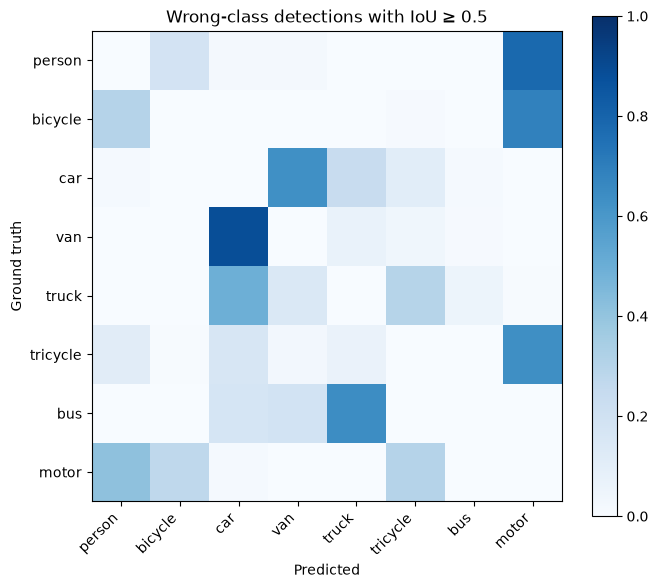

,n_gt,missed,bg,conf,miss_rate
video,,,,,
uav0000145_00000_v,696,450,33,50,0.647
uav0000288_00001_v,13062,6224,1001,1780,0.476
uav0000138_00000_v,6155,2929,134,196,0.476
uav0000072_06432_v,1806,825,153,54,0.457
uav0000289_00001_v,3551,1533,263,442,0.432
uav0000239_03720_v,3142,1013,482,267,0.322
uav0000079_00480_v,2501,785,75,46,0.314
uav0000266_04830_v,146,40,0,5,0.274


In [ ]:
err_df, confusion_counts, size_table = analyze(preds, val_dataset)
size_table['recall_class_aware'] = size_table.found_correct_class / size_table.n_gt.replace(0, np.nan)
size_table['recall_class_agnostic'] = size_table.found_any_class / size_table.n_gt.replace(0, np.nan)
display(size_table.round(3))
print('Error totals:', err_df[['tp', 'dup', 'conf', 'loc', 'bg', 'missed', 'ignored']].sum().to_dict())
err_df.to_csv(OUT / 'failure_counts.csv', index=False)

labels = [CATS[category_id] for category_id in CAT_IDS]
confusion_matrix = confusion_counts[1:, 1:]
confusion_matrix = confusion_matrix / np.maximum(confusion_matrix.sum(axis=1, keepdims=True), 1)
fig, ax = plt.subplots(figsize=(7, 6))
matrix_image = ax.imshow(confusion_matrix, cmap='Blues', vmin=0, vmax=1)
ax.set_xticks(range(len(labels)), labels, rotation=45, ha='right')
ax.set_yticks(range(len(labels)), labels)
ax.set_xlabel('Predicted')
ax.set_ylabel('Ground truth')
ax.set_title('Wrong-class detections with IoU ≥ 0.5')
plt.colorbar(matrix_image)
plt.tight_layout()
plt.savefig(OUT / 'confusion_matrix.png', dpi=150)
plt.show()
display(err_df.groupby('video')[['n_gt', 'missed', 'bg', 'conf']].sum()
        .assign(miss_rate=lambda table: table.missed/table.n_gt.replace(0, np.nan))
        .sort_values('miss_rate', ascending=False).head(8).round(3))

In [ ]:
def show_case(image_id, title, threshold=SCORE_THRESHOLD):
    indices = {int(image_info['id']): i for i, image_info in enumerate(val_dataset.images)}
    k = indices[image_id]
    img, target = val_dataset[k]
    prediction = pred_by_id[image_id]
    keep = prediction['scores'] >= threshold
    fig, ax = plt.subplots(figsize=(14, 8))
    ax.imshow(img.permute(1, 2, 0))
    for box in target['boxes'].tolist():
        ax.add_patch(Rectangle((box[0], box[1]), box[2]-box[0], box[3]-box[1],
                               fill=False, edgecolor='lime', linewidth=1))
    for box in prediction['boxes'][keep].tolist():
        ax.add_patch(Rectangle((box[0], box[1]), box[2]-box[0], box[3]-box[1],
                               fill=False, edgecolor='red', linewidth=.8, linestyle=':'))
    for box in target['ignored'].tolist():
        ax.add_patch(Rectangle((box[0], box[1]), box[2]-box[0], box[3]-box[1],
                               fill=False, edgecolor='yellow', linewidth=1.5, linestyle='--'))
    ax.set_title(f"{title} | {val_dataset.images[k].get('video', 'unknown')} | green=GT red=prediction yellow=ignore")
    ax.axis('off')
    plt.tight_layout()
    return fig

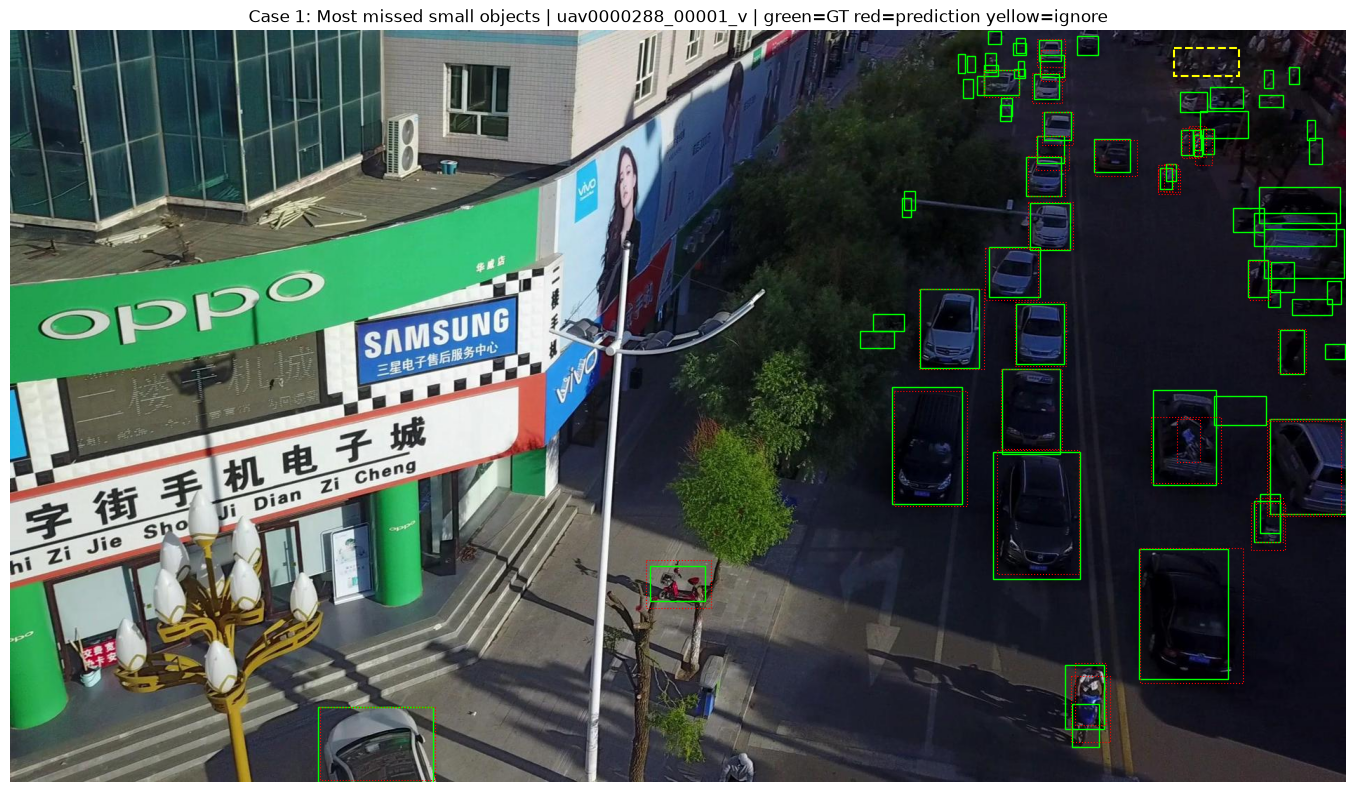

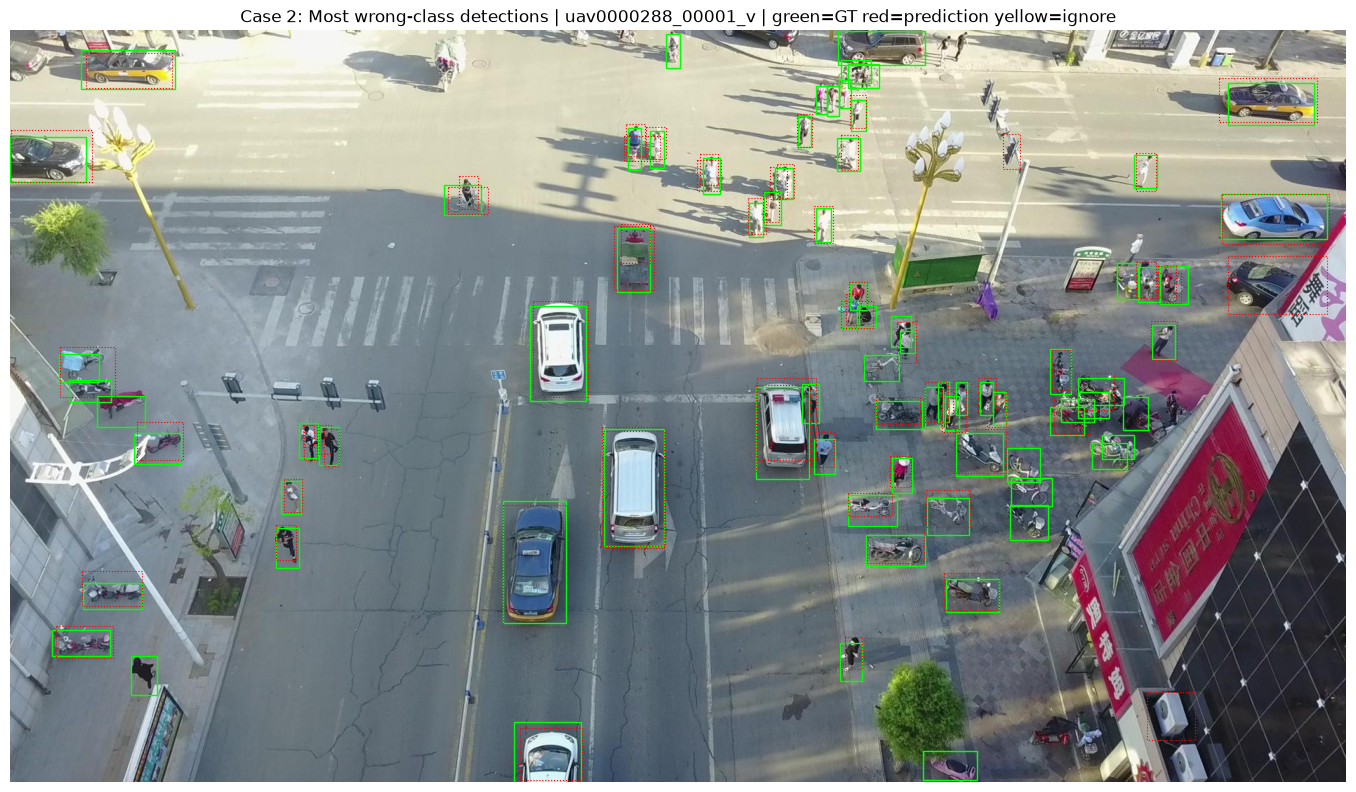

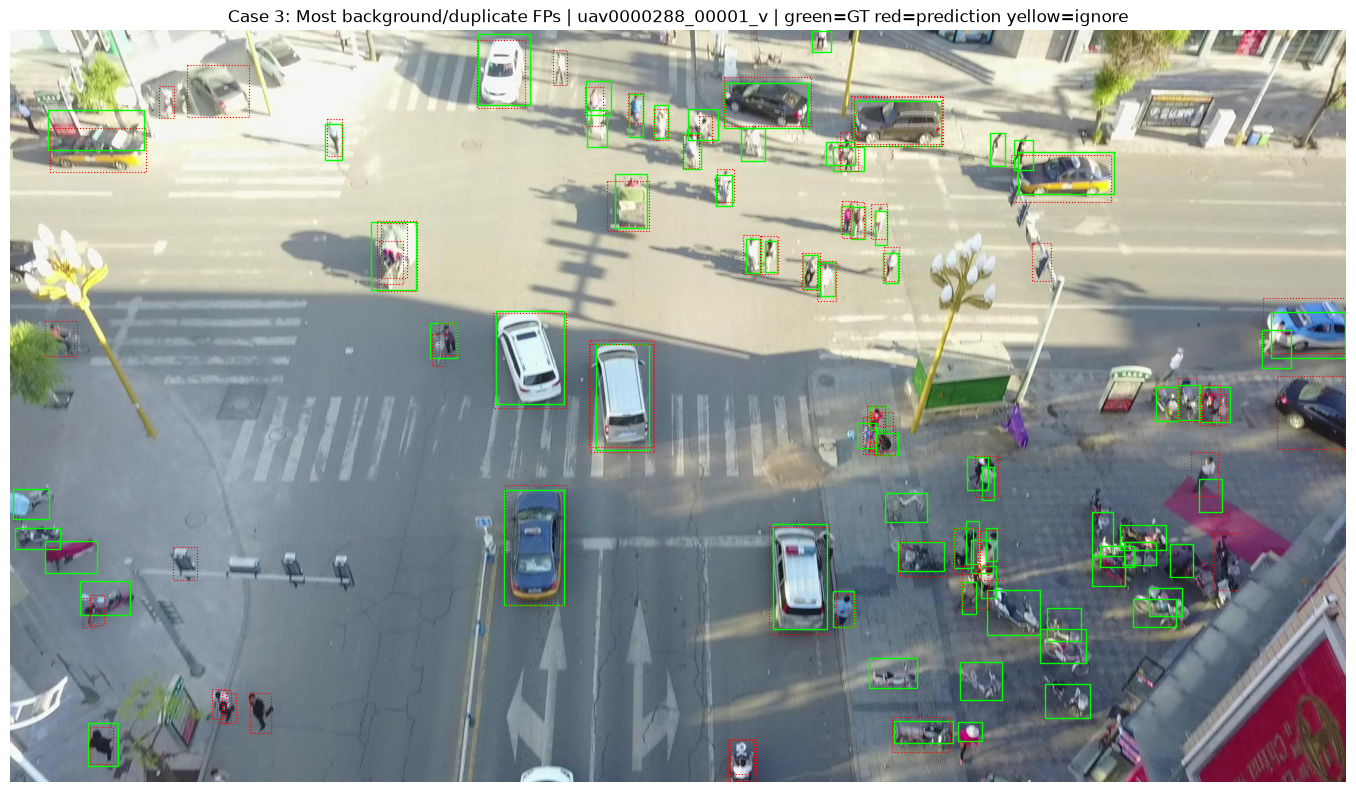

Inspect the three frames and explain the likely causes in your report.


In [ ]:
cases = [
    ('Most missed small objects', int(err_df.sort_values('missed_small', ascending=False).image_id.iloc[0])),
    ('Most wrong-class detections', int(err_df.sort_values('conf', ascending=False).image_id.iloc[0])),
    ('Most background/duplicate FPs', int(err_df.assign(fp=err_df.bg+err_df.dup).sort_values('fp', ascending=False).image_id.iloc[0])),
]
for i, (title, image_id) in enumerate(cases, 1):
    fig = show_case(image_id, f'Case {i}: {title}')
    fig.savefig(OUT / f'failure_case_{i}.png', dpi=150)
    plt.show()
print('Inspect the three frames and explain the likely causes in your report.')

### Official validation


In [ ]:
official_ids = [int(image_info['id']) for image_info in coco_val['images']]
official_dataset = VisDrone(DATA, 'val', coco_val, official_ids)
official_loader = make_loader(official_dataset, 4, workers=0)
official_gt = make_gt(coco_val, official_ids)

In [ ]:
rows = []
for name, fold in all_results:
    model = load_model(name, fold)
    metrics = coco_metrics(predict(model, official_loader), official_gt)
    rows.append(dict(run=name, fold=fold, **{k: metrics[k] for k in KEYS}, ms_per_img=measure_speed(model, official_dataset)))
    del model
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()

In [ ]:
official = pd.DataFrame(rows)
official.to_csv(OUT / 'official_val_folds.csv', index=False)
official_summary, official_table = mean_std(official)
official_summary.to_csv(OUT / 'official_val_summary.csv')
official_table.to_csv(OUT / 'official_val_mean_std.csv')
display(official_table)
print('Selected by cross-validation:', BEST, '| official val mAP:', official_table.loc[BEST, 'mAP'])

,mAP,AP50,AP75,APs,APm,APl,AR,ms_per_img
run,,,,,,,,
lr_scheduler,0.1909 ± 0.0062,0.3937 ± 0.0074,0.1629 ± 0.0090,0.0879 ± 0.0074,0.1716 ± 0.0023,0.3612 ± 0.0121,0.3232 ± 0.0099,25.5302 ± 0.1071
baseline,0.1888 ± 0.0085,0.3926 ± 0.0075,0.1569 ± 0.0150,0.0842 ± 0.0059,0.1678 ± 0.0042,0.3597 ± 0.0198,0.3275 ± 0.0186,25.7451 ± 0.2904
giou_loss,0.1845 ± 0.0076,0.3862 ± 0.0096,0.1532 ± 0.0110,0.0848 ± 0.0075,0.1642 ± 0.0020,0.3502 ± 0.0207,0.3300 ± 0.0254,25.7568 ± 0.2365


Selected by cross-validation: lr_scheduler | official val mAP: 0.1909 ± 0.0062


## Final Model Evaluation and Testing

In [ ]:
import os, sys
from pathlib import Path
import pandas as pd
from IPython.display import display

ROOT = Path(os.environ.get('UCU_HW2_ROOT', Path('..').resolve()))
os.environ['UCU_HW2_ROOT'] = str(ROOT)
sys.path.insert(0, str(ROOT / 'shared'))
import final_evaluation

In [ ]:
MODEL = 'faster_rcnn'
print('GPU:', final_evaluation.gpu_status())
print('COCO evaluation config id:', final_evaluation.EVAL_ID, '| speed protocol id:', final_evaluation.SPEED_ID)
overlap = final_evaluation.overlap_check()
print({k: overlap[k] for k in ('shared_video_names', 'shared_source_flights', 'identical_files_train_val',
                               'identical_files_train_test', 'identical_files_val_test', 'test_labels_available')})

GPU: {'gpu': 'NVIDIA GeForce RTX 5070', 'utilization_pct': 3, 'memory_used_mib': 1243, 'memory_total_mib': 12227}
COCO evaluation config id: 639cae7b8a2dd79e | speed protocol id: 0eb0c2f5d2535e81
{'shared_video_names': [], 'shared_source_flights': [], 'identical_files_train_val': 0, 'identical_files_train_test': 0, 'identical_files_val_test': 0, 'test_labels_available': False}


In [ ]:
inventory = final_evaluation.training_inventory()
final_evaluation.save_csv(inventory, final_evaluation.FINAL / 'audit' / 'training_inventory.csv')
model_inventory = inventory[inventory.model == final_evaluation.MODELS[MODEL]['label']]
display(model_inventory[['experiment', 'fold', 'status', 'completed_epochs', 'best_epoch', 'cv_map', 'trained_on', 'issues']]
        .round(4))
assert (model_inventory.status == 'complete').all(), 'incomplete or inconsistent run: see the issues column'

,experiment,fold,status,completed_epochs,best_epoch,cv_map,trained_on,issues
0,baseline,0,complete,6,5,0.2332,local RTX 5070 (mid-epoch resume supported; re...,none
1,baseline,1,complete,6,1,0.2232,local RTX 5070 (mid-epoch resume supported; re...,none
2,baseline,2,complete,6,6,0.2319,local RTX 5070 (mid-epoch resume supported; re...,none
3,baseline,3,complete,6,5,0.2028,local RTX 5070 (mid-epoch resume supported; re...,none
4,baseline,4,complete,6,5,0.1489,local RTX 5070 (mid-epoch resume supported; re...,none
5,giou_loss,0,complete,6,4,0.2305,local RTX 5070 (mid-epoch resume supported; re...,none
6,giou_loss,1,complete,6,1,0.2260,local RTX 5070 (mid-epoch resume supported; re...,none
7,giou_loss,2,complete,6,4,0.2361,local RTX 5070 (mid-epoch resume supported; re...,none
8,giou_loss,3,complete,6,3,0.2062,local RTX 5070 (mid-epoch resume supported; re...,none
9,giou_loss,4,complete,6,4,0.1510,local RTX 5070 (mid-epoch resume supported; re...,none


In [ ]:
official, checks = final_evaluation.run_official_evaluation(MODEL, final_evaluation.VERIFY[MODEL])
print('Stored vs recomputed (identical checkpoints):')
display(checks[['experiment', 'fold', 'stored_mAP', 'recomputed_mAP', 'max_abs_diff_all_metrics', 'agrees']].round(5))
display(official.pivot(index='experiment', columns='fold', values='mAP').round(4))

Stored vs recomputed (identical checkpoints):


,experiment,fold,stored_mAP,recomputed_mAP,max_abs_diff_all_metrics,agrees
0,lr_scheduler,4,0.19353,0.19353,0.0,True
1,baseline,0,0.19426,0.19426,0.0,True


fold,0,1,2,3,4
experiment,,,,,
baseline,0.1943,0.1774,0.1910,0.1832,0.1982
giou_loss,0.1878,0.1713,0.1892,0.1852,0.1892
lr_scheduler,0.1960,0.1858,0.1962,0.1828,0.1935


### Inference speed

In [ ]:
cv_mean = {experiment: sum(final_evaluation.load_result(MODEL, experiment, fold)['metrics']['mAP']
                           for fold in final_evaluation.FOLDS) / 5
           for experiment in final_evaluation.MODELS[MODEL]['experiments']}
BEST_CV = max(cv_mean, key=cv_mean.get)
REPRESENTATIVE_FOLD = final_evaluation.representative_fold(official, BEST_CV)
speed = final_evaluation.run_speed(MODEL, representative=(BEST_CV, REPRESENTATIVE_FOLD))
display(speed.groupby(['experiment', 'batch_size', 'precision'])[['ms_per_image', 'fps']].agg(['mean', 'std']).round(1))

ms_per_image        fps     
                                          mean  std  mean  std
experiment   batch_size precision                             
baseline     1          amp_fp16          27.0  0.1  37.1  0.2
             4          amp_fp16          27.6  0.1  36.2  0.1
giou_loss    1          amp_fp16          27.3  0.3  36.7  0.4
             4          amp_fp16          27.9  0.3  35.8  0.3
lr_scheduler 1          amp_fp16          27.2  0.2  36.8  0.2
                        fp32              33.7  NaN  29.7  NaN
             4          amp_fp16          27.9  0.2  35.9  0.3

### Fold-level metrics, mean ± std and selection

In [ ]:
section = final_evaluation.model_section(MODEL)
summary = section['summary']
metric_columns = ['map', 'map_50', 'map_75', 'map_small', 'map_medium', 'map_large', 'ar', 'ms_per_image']
table = summary.set_index(['evaluation_split', 'experiment'])
display(pd.DataFrame({column: table[column + '_mean'].map('{:.4f}'.format)
                              + ' ± ' + table[column + '_std'].map('{:.4f}'.format)
                      for column in metric_columns}))
print({k: section['selection'][k] for k in ('best_by_cv', 'best_by_official_val', 'agree', 'representative_fold')})

,,map,map_50,map_75,map_small,map_medium,map_large,ar,ms_per_image
evaluation_split,experiment,,,,,,,,
cv_out_of_fold,baseline,0.2080 ± 0.0352,0.4106 ± 0.0515,0.1887 ± 0.0430,0.0740 ± 0.0271,0.1953 ± 0.0144,0.3839 ± 0.0405,0.3513 ± 0.0567,26.9864 ± 0.1273
official_val,baseline,0.1888 ± 0.0085,0.3926 ± 0.0075,0.1569 ± 0.0150,0.0842 ± 0.0059,0.1678 ± 0.0042,0.3597 ± 0.0198,0.3275 ± 0.0186,26.9864 ± 0.1273
cv_out_of_fold,giou_loss,0.2100 ± 0.0348,0.4148 ± 0.0524,0.1903 ± 0.0415,0.0727 ± 0.0241,0.1943 ± 0.0161,0.3828 ± 0.0476,0.3500 ± 0.0521,27.2730 ± 0.3221
official_val,giou_loss,0.1845 ± 0.0076,0.3862 ± 0.0096,0.1532 ± 0.0110,0.0848 ± 0.0075,0.1642 ± 0.0020,0.3502 ± 0.0207,0.3300 ± 0.0254,27.2730 ± 0.3221
cv_out_of_fold,lr_scheduler,0.2110 ± 0.0337,0.4137 ± 0.0489,0.1925 ± 0.0410,0.0757 ± 0.0276,0.1981 ± 0.0132,0.3856 ± 0.0507,0.3450 ± 0.0404,27.2043 ± 0.1821
official_val,lr_scheduler,0.1909 ± 0.0062,0.3937 ± 0.0074,0.1629 ± 0.0090,0.0879 ± 0.0074,0.1716 ± 0.0023,0.3612 ± 0.0121,0.3232 ± 0.0099,27.2043 ± 0.1821


{'best_by_cv': 'lr_scheduler', 'best_by_official_val': 'lr_scheduler', 'agree': True, 'representative_fold': 4}


### Inference tests and failure analysis

In [ ]:
selection = section['selection']
failures = final_evaluation.failure_section(MODEL, selection['best_by_cv'], selection['representative_fold'])
print(f"{selection['best_by_cv']} fold {selection['representative_fold']} | score threshold {failures['threshold']:.2f} |",
      failures['totals'])
display(pd.DataFrame(failures['recall_by_size']).round(3))
display(pd.DataFrame(failures['cases'])[['title', 'video', 'frame_id', 'n_gt', 'tp', 'missed', 'missed_small',
                                         'classification', 'localization', 'background']])

lr_scheduler fold 4 | score threshold 0.55 | {'tp': 59168, 'duplicate': 270, 'classification': 8272, 'localization': 5533, 'background': 10586, 'ignored': 7282, 'missed': 54964, 'n_gt': 114132}


,size,n_gt,missed,recall
0,small,21910,14296,0.348
1,medium,79357,37437,0.528
2,large,12865,3231,0.749


,title,video,frame_id,n_gt,tp,missed,missed_small,classification,localization,background
0,most missed small objects (false negatives),uav0000182_00000_v,190,57,14,43,29,8,5,9
1,most classification errors,uav0000182_00000_v,239,72,34,38,18,19,6,26
2,most localization errors,uav0000137_00458_v,166,104,53,51,2,12,15,4
3,most background false positives,uav0000305_00000_v,150,26,17,9,1,3,1,28
